In [1]:

#Q1
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

# Download required resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Original paragraph
text = """
I love Artificial Intelligence because it makes technology smarter.
AI helps people solve complex problems and automate repetitive tasks.
Machine learning allows computers to learn from data and improve performance.
I enjoy exploring AI applications in healthcare, education, and robotics.
Artificial Intelligence is transforming the world and creating exciting opportunities.
"""

# 1. Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

# 2. Tokenize into words and sentences
words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

# 3. Compare split() and word_tokenize()
print("\nUsing split():", clean_text.split())
print("\nUsing word_tokenize():", word_tokenize(text))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("\nWords after Stopword Removal:\n", filtered_words)

# 5. Word frequency distribution
frequency = Counter(filtered_words)

print("\nWord Frequency Distribution:")
for word, count in frequency.most_common():
    print(word, ":", count)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Cleaned Text:
 
i love artificial intelligence because it makes technology smarter
ai helps people solve complex problems and automate repetitive tasks
machine learning allows computers to learn from data and improve performance
i enjoy exploring ai applications in healthcare education and robotics
artificial intelligence is transforming the world and creating exciting opportunities


Word Tokens:
 ['i', 'love', 'artificial', 'intelligence', 'because', 'it', 'makes', 'technology', 'smarter', 'ai', 'helps', 'people', 'solve', 'complex', 'problems', 'and', 'automate', 'repetitive', 'tasks', 'machine', 'learning', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'and', 'improve', 'performance', 'i', 'enjoy', 'exploring', 'ai', 'applications', 'in', 'healthcare', 'education', 'and', 'robotics', 'artificial', 'intelligence', 'is', 'transforming', 'the', 'world', 'and', 'creating', 'exciting', 'opportunities']

Sentence Tokens:
 ['\nI love Artificial Intelligence because it makes techno

In [2]:
#Q2

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Use the same paragraph from Q1
text = """
I love Artificial Intelligence because it makes technology smarter.
AI helps people solve complex problems and automate repetitive tasks.
Machine learning allows computers to learn from data and improve performance.
I enjoy exploring AI applications in healthcare, education, and robotics.
Artificial Intelligence is transforming the world and creating exciting opportunities.
"""

# 1. Extract alphabetic words
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic Words:\n", words)

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("\nAfter Stopword Removal:\n", filtered_words)

# 3. Stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]

print("\nStemmed Words:\n", stemmed_words)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words]

print("\nLemmatized Words:\n", lemmatized_words)

# 5. Compare outputs
print("\nComparison:")
for original, stem, lemma in zip(filtered_words, stemmed_words, lemmatized_words):
    print(original, "-> Stem:", stem, "| Lemma:", lemma)


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Alphabetic Words:
 ['i', 'love', 'artificial', 'intelligence', 'because', 'it', 'makes', 'technology', 'smarter', 'ai', 'helps', 'people', 'solve', 'complex', 'problems', 'and', 'automate', 'repetitive', 'tasks', 'machine', 'learning', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'and', 'improve', 'performance', 'i', 'enjoy', 'exploring', 'ai', 'applications', 'in', 'healthcare', 'education', 'and', 'robotics', 'artificial', 'intelligence', 'is', 'transforming', 'the', 'world', 'and', 'creating', 'exciting', 'opportunities']

After Stopword Removal:
 ['love', 'artificial', 'intelligence', 'makes', 'technology', 'smarter', 'ai', 'helps', 'people', 'solve', 'complex', 'problems', 'automate', 'repetitive', 'tasks', 'machine', 'learning', 'allows', 'computers', 'learn', 'data', 'improve', 'performance', 'enjoy', 'exploring', 'ai', 'applications', 'healthcare', 'education', 'robotics', 'artificial', 'intelligence', 'transforming', 'world', 'creating', 'exciting', 'opportunities']



In [3]:
#Q3

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Three sample texts
texts = [
    "Artificial intelligence improves healthcare and education.",
    "Machine learning helps artificial intelligence analyze data.",
    "Blockchain technology provides secure decentralized transactions."
]

# 1. Bag of Words
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("Bag of Words:")
print(count_vectorizer.get_feature_names_out())
print(bow_matrix.toarray())

# 2. TF-IDF
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())

# 3. Top 3 keywords for each text
feature_names = tfidf_vectorizer.get_feature_names_out()

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[-3:][::-1]

    print(f"\nText {i+1}: {text}")
    print("Top 3 Keywords:")

    for index in top_indices:
        print(feature_names[index], ":", round(scores[index], 3))


Bag of Words:
['analyze' 'and' 'artificial' 'blockchain' 'data' 'decentralized'
 'education' 'healthcare' 'helps' 'improves' 'intelligence' 'learning'
 'machine' 'provides' 'secure' 'technology' 'transactions']
[[0 1 1 0 0 0 1 1 0 1 1 0 0 0 0 0 0]
 [1 0 1 0 1 0 0 0 1 0 1 1 1 0 0 0 0]
 [0 0 0 1 0 1 0 0 0 0 0 0 0 1 1 1 1]]

TF-IDF Matrix:
[[0.         0.44036207 0.3349067  0.         0.         0.
  0.44036207 0.44036207 0.         0.44036207 0.3349067  0.
  0.         0.         0.         0.         0.        ]
 [0.40301621 0.         0.30650422 0.         0.40301621 0.
  0.         0.         0.40301621 0.         0.30650422 0.40301621
  0.40301621 0.         0.         0.         0.        ]
 [0.         0.         0.         0.40824829 0.         0.40824829
  0.         0.         0.         0.         0.         0.
  0.         0.40824829 0.40824829 0.40824829 0.40824829]]

Text 1: Artificial intelligence improves healthcare and education.
Top 3 Keywords:
improves : 0.44
education 

In [4]:
#Q4

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Two texts
text1 = """
Artificial intelligence enables machines to learn from data.
AI systems perform prediction and intelligent decision making.
Machine learning is an important part of artificial intelligence.
AI is used in healthcare, education, and automation.
"""

text2 = """
Blockchain is a decentralized digital ledger.
Blockchain stores transactions securely across multiple computers.
Cryptography protects blockchain data from unauthorized changes.
Blockchain is used in cryptocurrency and digital payments.
"""

# 1. Preprocessing
def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    return text.split()

words1 = preprocess(text1)
words2 = preprocess(text2)

print("Text 1 Tokens:", words1)
print("\nText 2 Tokens:", words2)

# 2(a). Jaccard Similarity
set1 = set(words1)
set2 = set(words2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\nCommon Words:", intersection)
print("Jaccard Similarity:", jaccard)

# 2(b). Cosine Similarity using TF-IDF
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(tfidf_matrix[0], tfidf_matrix[1])[0][0]

print("Cosine Similarity:", cosine)

# 2(c). Analysis
if jaccard > cosine:
    print("Jaccard similarity is higher.")
else:
    print("Cosine similarity is higher.")


Text 1 Tokens: ['artificial', 'intelligence', 'enables', 'machines', 'to', 'learn', 'from', 'data', 'ai', 'systems', 'perform', 'prediction', 'and', 'intelligent', 'decision', 'making', 'machine', 'learning', 'is', 'an', 'important', 'part', 'of', 'artificial', 'intelligence', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'automation']

Text 2 Tokens: ['blockchain', 'is', 'a', 'decentralized', 'digital', 'ledger', 'blockchain', 'stores', 'transactions', 'securely', 'across', 'multiple', 'computers', 'cryptography', 'protects', 'blockchain', 'data', 'from', 'unauthorized', 'changes', 'blockchain', 'is', 'used', 'in', 'cryptocurrency', 'and', 'digital', 'payments']

Common Words: {'used', 'is', 'from', 'and', 'data', 'in'}
Jaccard Similarity: 0.13333333333333333
Cosine Similarity: 0.1338975464776919
Cosine similarity is higher.



Review: This laptop is amazing and performs very well.
Polarity: 0.4
Subjectivity: 0.6
Sentiment: Positive

Review: The battery life is excellent and the display is beautiful.
Polarity: 0.925
Subjectivity: 1.0
Sentiment: Positive

Review: I love this product. It is fast and easy to use.
Polarity: 0.378
Subjectivity: 0.678
Sentiment: Positive

Review: The laptop is terrible and extremely slow.
Polarity: -0.65
Subjectivity: 0.7
Sentiment: Negative

Review: The keyboard is bad and the battery drains quickly.
Polarity: -0.183
Subjectivity: 0.583
Sentiment: Negative

Review: The product is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive


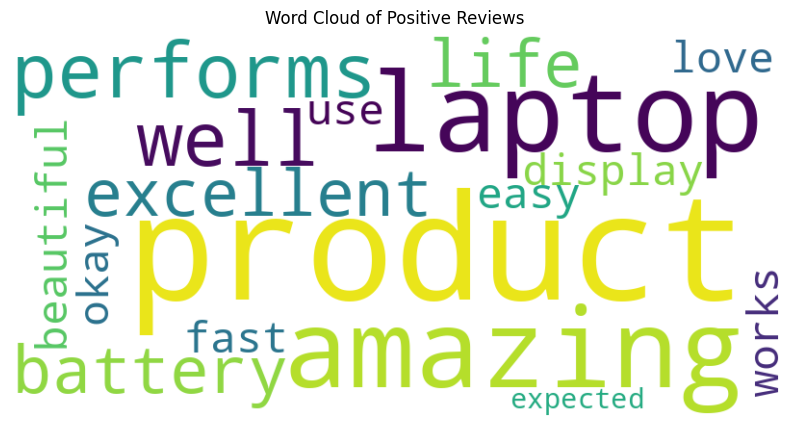

In [5]:
#Q5

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Sample product reviews
reviews = [
    "This laptop is amazing and performs very well.",
    "The battery life is excellent and the display is beautiful.",
    "I love this product. It is fast and easy to use.",
    "The laptop is terrible and extremely slow.",
    "The keyboard is bad and the battery drains quickly.",
    "The product is okay and works as expected."
]

positive_reviews = []

# 1. Calculate polarity and subjectivity
# 2. Classify reviews
for review in reviews:
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)

# 3. Word Cloud for positive reviews
positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white",
    colormap="viridis"
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()


In [6]:
#Q6

import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training paragraph (~100 words)
text = """
Artificial intelligence is changing the world.
Technology helps people solve problems and improve their lives.
Machine learning enables computers to learn from data.
Deep learning uses neural networks to understand complex patterns.
Artificial intelligence is used in healthcare, education, business and science.
Computers can recognize images, understand language and make predictions.
Researchers develop intelligent systems to automate repetitive tasks.
Technology continues to evolve and creates new opportunities.
Artificial intelligence can improve productivity and support innovation.
The future of technology depends on responsible development and creativity.
"""

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("Word Index:")
print(tokenizer.word_index)

# 3. Create input sequences
input_sequences = []

for sentence in text.split("."):
    sentence = sentence.strip()

    if sentence:
        token_list = tokenizer.texts_to_sequences([sentence])[0]

        for i in range(1, len(token_list)):
            n_gram_sequence = token_list[:i+1]
            input_sequences.append(n_gram_sequence)

# 4. Padding
max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

# 5. Separate input and output
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

# One-hot encode output
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

# 6. Build LSTM model
model = Sequential([
    Embedding(total_words, 50, input_length=max_sequence_len-1),
    LSTM(100),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

# 7. Train the model
model.fit(X, y, epochs=200, verbose=1)

# 8. Generate text
def generate_text(seed_text, next_words=20):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len-1,
            padding='pre'
        )

        predicted = model.predict(token_list, verbose=0)
        predicted_index = np.argmax(predicted)

        output_word = ""

        for word, index in tokenizer.word_index.items():
            if index == predicted_index:
                output_word = word
                break

        if not output_word:
            break

        seed_text += " " + output_word

    return seed_text

# Seed word
seed = "artificial intelligence"

print("\nGenerated Text:")
print(generate_text(seed, 20))


Word Index:
{'and': 1, 'to': 2, 'artificial': 3, 'intelligence': 4, 'technology': 5, 'is': 6, 'the': 7, 'improve': 8, 'learning': 9, 'computers': 10, 'understand': 11, 'can': 12, 'changing': 13, 'world': 14, 'helps': 15, 'people': 16, 'solve': 17, 'problems': 18, 'their': 19, 'lives': 20, 'machine': 21, 'enables': 22, 'learn': 23, 'from': 24, 'data': 25, 'deep': 26, 'uses': 27, 'neural': 28, 'networks': 29, 'complex': 30, 'patterns': 31, 'used': 32, 'in': 33, 'healthcare': 34, 'education': 35, 'business': 36, 'science': 37, 'recognize': 38, 'images': 39, 'language': 40, 'make': 41, 'predictions': 42, 'researchers': 43, 'develop': 44, 'intelligent': 45, 'systems': 46, 'automate': 47, 'repetitive': 48, 'tasks': 49, 'continues': 50, 'evolve': 51, 'creates': 52, 'new': 53, 'opportunities': 54, 'productivity': 55, 'support': 56, 'innovation': 57, 'future': 58, 'of': 59, 'depends': 60, 'on': 61, 'responsible': 62, 'development': 63, 'creativity': 64}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.0400 - loss: 4.1744  
Epoch 2/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.0667 - loss: 4.1655 
Epoch 3/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.0800 - loss: 4.1581
Epoch 4/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1067 - loss: 4.1491
Epoch 5/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1333 - loss: 4.1387
Epoch 6/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.1200 - loss: 4.1241
Epoch 7/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.0933 - loss: 4.0984
Epoch 8/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0800 - loss: 4.0620
Epoch 9/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.0800 - loss: 4.0130
Epoch 10/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.0800 - loss: 3.9469
Epoch 11/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0933 - loss: 3.9241
Epoch 12/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1333 -